# Machine Learning Midterm — Breast Cancer Wisconsin

This notebook covers Sections 1–10 for the **Breast Cancer Wisconsin** dataset only.
Shared functions live in `helpers.py`; all data, models and results in this notebook belong to this dataset.
Run with **Kernel → Restart & Run All**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

DATASET = "breast_cancer"
DATASET_TITLE = "Breast Cancer Wisconsin"
N_CLUSTERS = 2            # fixed by the assignment (class count)
POSITIVE_LABEL = 0     # malignant (original class 0) is the positive class
MANUAL_CHECK_CLASS = 0    # class used for the manual precision/recall/F1 check

print("Seeds:", H.SEEDS, "| test seed:", H.TEST_SEED, "| final evaluation seed:", H.EVAL_SEED)
print("Tree depths:", H.TREE_DEPTHS, "| KNN neighbours:", H.KNN_NEIGHBORS)
H.make_output_dirs()
H.package_versions()

Seeds: [42, 52, 62] | test seed: 42 | final evaluation seed: 42
Tree depths: [2, 3, 5, 10, None] | KNN neighbours: [1, 3, 5, 7, 11]


,package,version
0,python,3.13.17
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.5.3
3,pandas,3.0.5
4,scikit-learn,1.9.1
5,scipy,1.18.1
6,matplotlib,3.11.2


## 1. Loading the Datasets
### 1.1 Load the dataset from scikit-learn

In [2]:
# Loaded with sklearn.datasets.load_breast_cancer (inside H.load_dataset)
X, y, target_names = H.load_dataset(DATASET)
print(type(X), type(y))

<class 'pandas.DataFrame'> <class 'pandas.Series'>


### 1.2 Create the data frames

In [3]:
print("Shape of X:", X.shape, "| shape of y:", y.shape)
print("Target is NOT in X:", "target" not in X.columns)
X.head()

Shape of X: (569, 30) | shape of y: (569,)
Target is NOT in X: True


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [4]:
print("Feature names:", list(X.columns))
print("Target labels:", sorted(y.unique()))
print("Target names:", target_names)
H.class_mapping_table(y, target_names)

Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target labels: [np.int64(0), np.int64(1)]
Target names: [np.str_('malignant'), np.str_('benign')]


,label,target_name,n_samples,percent
0,0,malignant,212,37.2600
1,1,benign,357,62.7400


> **Interpretation (write your own):** Number of samples/features, the class-label mapping (0 = malignant = positive class, 1 = benign) and whether the classes are balanced.

## 2. Dataset Quality Checks
### 2.1 Missing values and duplicates

In [5]:
missing = H.missing_values_table(X)
n_missing = int(missing["missing_count"].sum())
n_duplicates = int(X.duplicated().sum())
print("Total missing values:", n_missing)
print("Duplicate rows (features only):", n_duplicates)
print("Duplicate rows (features + target):", int(pd.concat([X, y], axis=1).duplicated().sum()))
if n_missing == 0:
    print("-> No missing values are present in any column.")
if n_duplicates == 0:
    print("-> No duplicate rows are present.")
NEEDS_IMPUTATION = n_missing > 0
missing.T

Total missing values: 0
Duplicate rows (features only): 0
Duplicate rows (features + target): 0
-> No missing values are present in any column.
-> No duplicate rows are present.


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 2.2 Potential outliers (IQR 1.5 rule and |z| > 3) — nothing is deleted or clipped

In [6]:
outliers = H.outlier_table(X)
print("Features with at least one IQR outlier:", int((outliers["IQR_outliers"] > 0).sum()), "of", X.shape[1])
outliers.head(10)

Features with at least one IQR outlier: 29 of 30


,IQR_lower,IQR_upper,IQR_outliers,z>3_outliers,IQR_outlier_%
area error,-23.1600,86.2000,65,6,11.4200
radius error,-0.1374,0.8487,38,7,6.6800
perimeter error,-1.0205,5.9835,38,8,6.6800
worst area,-337.7500,1937.0500,35,10,6.1500
smoothness error,0.0007,0.0126,30,7,5.2700
fractal dimension error,-0.0012,0.0080,28,10,4.9200
compactness error,-0.0160,0.0615,28,12,4.9200
symmetry error,0.0027,0.0360,27,11,4.7500
mean area,-123.3000,1326.3000,25,8,4.3900
worst fractal dimension,0.0405,0.1230,24,9,4.2200


### 2.3 Data types

In [7]:
dtypes, n_num, n_cat = H.dtype_summary(X)
print("Numerical features:", n_num, "| categorical features:", n_cat)
print(dtypes["dtype"].value_counts())
dtypes.T

Numerical features: 30 | categorical features: 0
dtype
float64    30
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


> **Interpretation (write your own):** State that there are no missing values/duplicates (or report them), that all features are numerical, and explain how large/small values affect the algorithms: KNN and K-Means use Euclidean distance, so extreme values and large-range features dominate distances; GaussianNB's mean/variance estimates are pulled by outliers; Decision Trees split on thresholds and are relatively robust. Outliers are kept.

## 3. Exploratory Data Analysis (EDA)
*Sections 2–3 are descriptive only; nothing here is used to select features, fit preprocessing or remove samples.*
### 3.1 Descriptive statistics

In [8]:
desc = H.descriptive_stats(X)
desc

,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


### 3.2 Class distribution and correlations

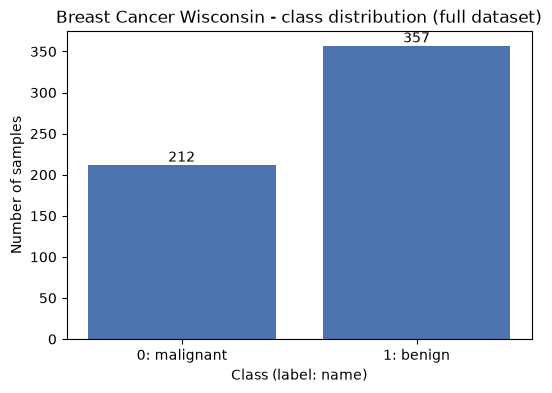

In [9]:
H.plot_class_distribution(y, target_names, DATASET_TITLE, f"{DATASET}_class_distribution")

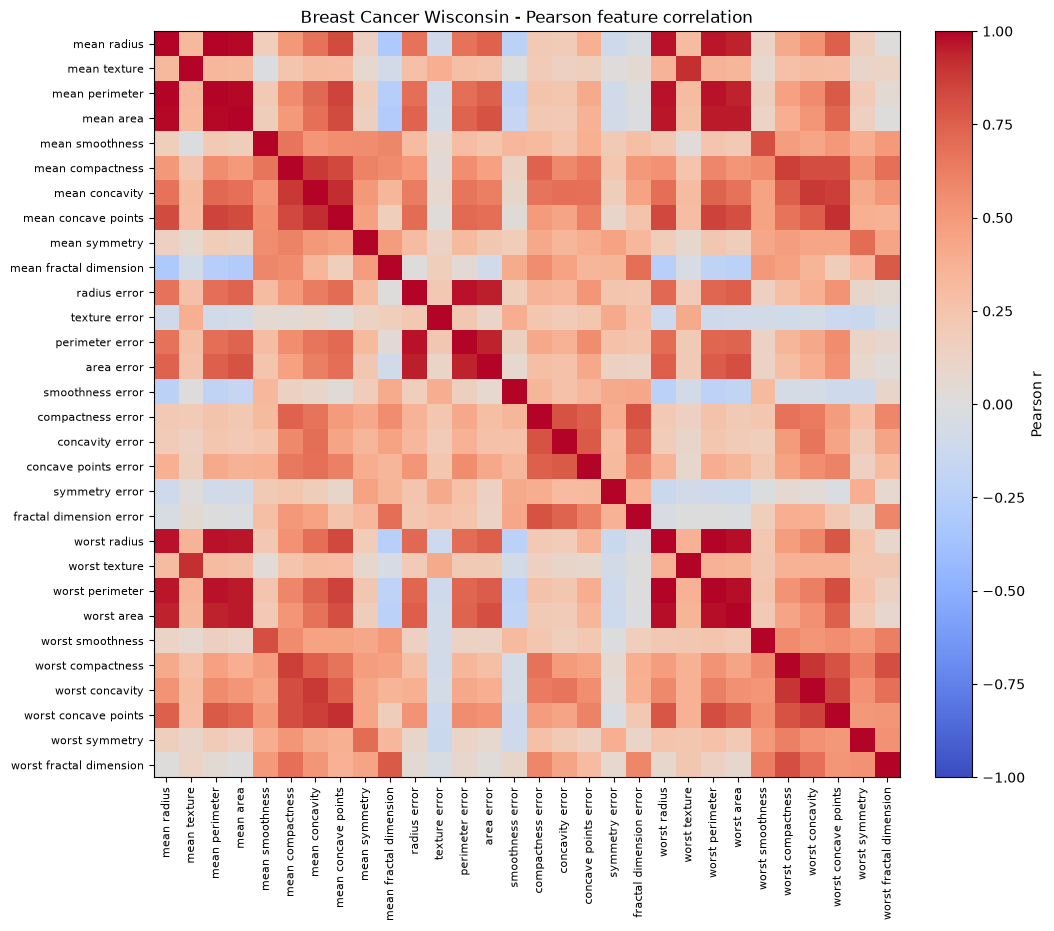

,feature_1,feature_2,r,abs_r
0,mean radius,mean perimeter,0.9979,0.9979
1,worst radius,worst perimeter,0.9937,0.9937
2,mean radius,mean area,0.9874,0.9874


In [10]:
corr = H.plot_correlation_heatmap(X, DATASET_TITLE, f"{DATASET}_correlation_heatmap")
top_pairs = H.top_correlated_pairs(corr, k=3)
top_pairs

### 3.3 Boxplots (each feature on its own scale)

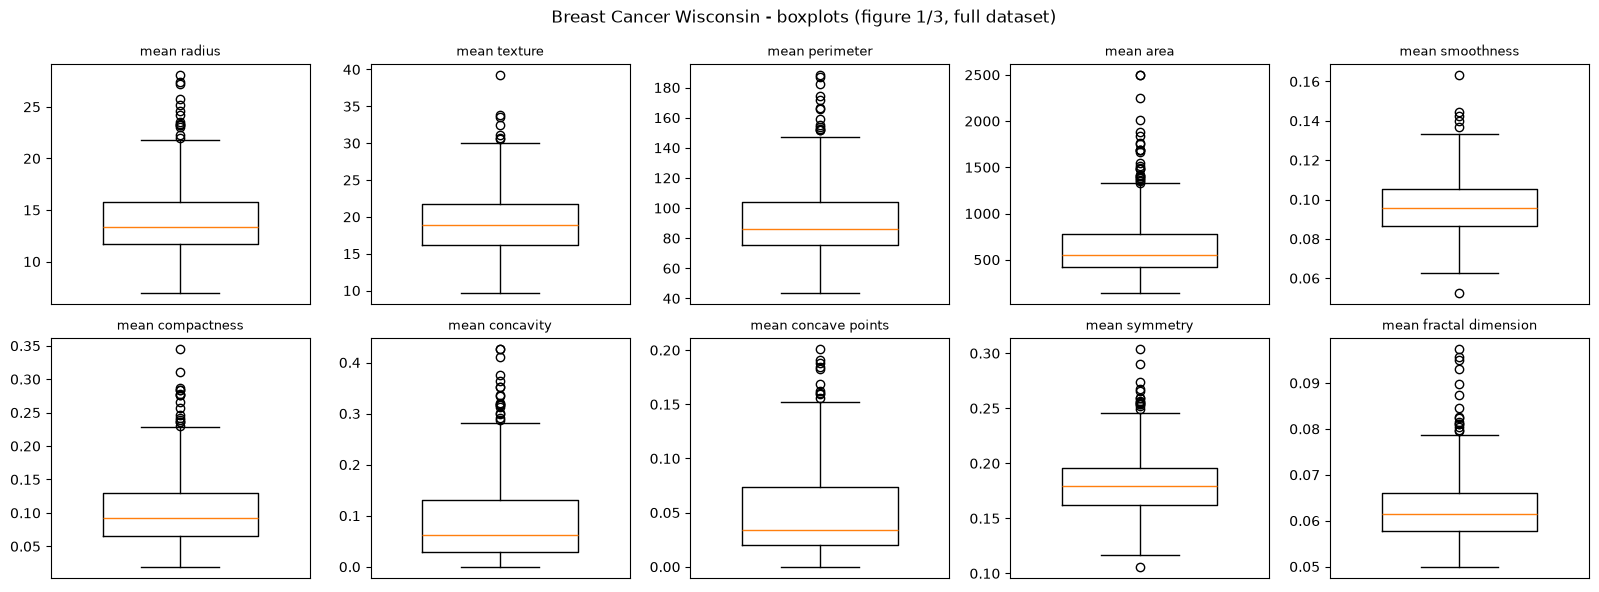

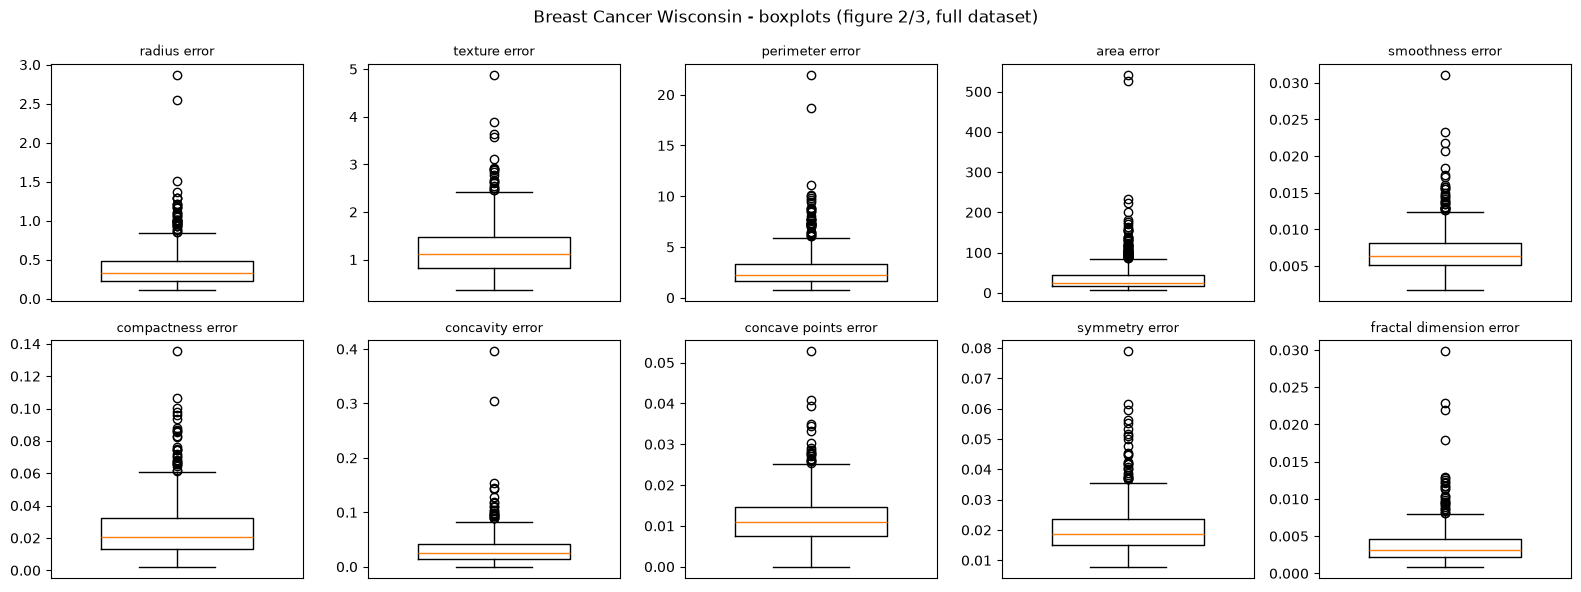

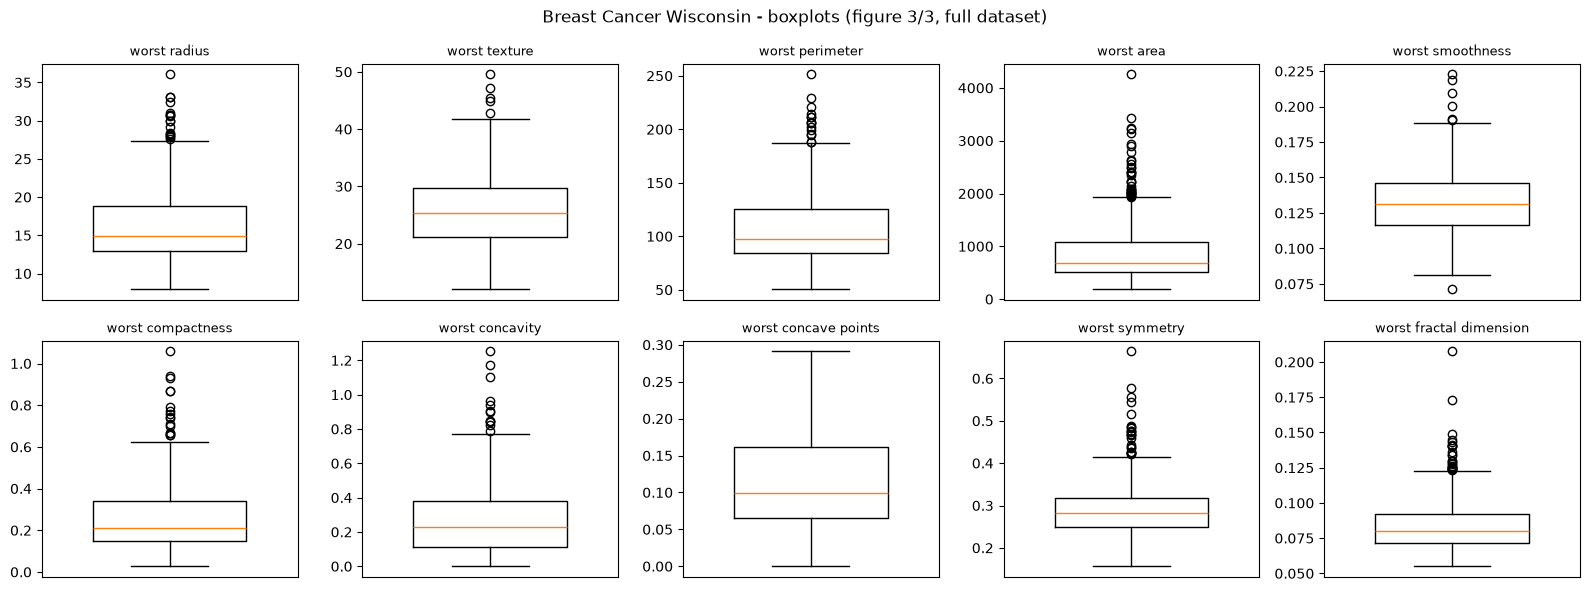

In [11]:
H.plot_boxplots(X, DATASET_TITLE, f"{DATASET}_boxplots", per_fig=10, ncols=5)

> **Interpretation (write your own):** Discuss the class balance, the three strongest unique correlated pairs above (and why they are related), and at least two boxplot observations about feature ranges/outliers (e.g. features whose ranges differ by orders of magnitude — the reason scaling matters for KNN and K-Means).

## 4. Splitting the Datasets
### 4.1 Fixed test set + three training/validation repetitions

In [12]:
X_test, y_test, splits = H.make_splits(X, y)
# Per-seed subsets are stored separately, e.g. splits[52]["X_train"]; original row indices are preserved.
for seed in H.SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, X_test {X_test.shape}")
print("First test indices:", list(X_test.index[:10]))

seed 42: X_train (398, 30), X_val (57, 30), X_test (114, 30)
seed 52: X_train (398, 30), X_val (57, 30), X_test (114, 30)
seed 62: X_train (398, 30), X_val (57, 30), X_test (114, 30)
First test indices: [256, 428, 501, 363, 564, 464, 358, 343, 516, 567]


### 4.2 Verify the split

In [13]:
split_table = H.split_summary(y, y_test, splits, target_names)
split_table.insert(0, "dataset", DATASET)
split_table

,dataset,seed,subset,n,percent,class_0_malignant,class_1_benign
0,breast_cancer,42,train,398,69.9500,149,249
1,breast_cancer,42,validation,57,10.0200,21,36
2,breast_cancer,42,test,114,20.0400,42,72
3,breast_cancer,52,train,398,69.9500,149,249
4,breast_cancer,52,validation,57,10.0200,21,36
5,breast_cancer,52,test,114,20.0400,42,72
6,breast_cancer,62,train,398,69.9500,149,249
7,breast_cancer,62,validation,57,10.0200,21,36
8,breast_cancer,62,test,114,20.0400,42,72


In [14]:
H.verify_splits(X, y_test, splits)

,seed,train∩val,train∩test,val∩test,sum_of_counts,dataset_size,covers_all_rows,test_indices_same_as_seed42
0,42,0,0,0,569,569,True,True
1,52,0,0,0,569,569,True,True
2,62,0,0,0,569,569,True,True


In [15]:
# Inspectable original row indices (saved to CSV for inspection)
split_indices = H.split_indices_table(y_test, splits)
split_indices.to_csv(H.RES_DIR / f"{DATASET}_split_indices.csv", index=False)
split_indices.groupby(["seed", "subset"]).row_index.apply(lambda s: list(s[:8])).to_frame("first 8 indices")

first 8 indices
seed subset                                              
42   test        [256, 428, 501, 363, 564, 464, 358, 343]
     train         [301, 390, 420, 356, 446, 56, 82, 221]
     validation     [454, 49, 50, 197, 393, 96, 333, 557]
52   test        [256, 428, 501, 363, 564, 464, 358, 343]
     train           [427, 81, 294, 47, 12, 46, 249, 348]
     validation  [142, 243, 135, 274, 263, 181, 254, 510]
62   test        [256, 428, 501, 363, 564, 464, 358, 343]
     train          [3, 508, 471, 379, 319, 56, 342, 279]
     validation     [61, 299, 410, 33, 134, 119, 36, 220]

> **Interpretation (write your own):** The test set is reserved once (random_state=42) and is identical in all repetitions; the seeds only change train/validation membership. Mention that repetitions overlap and are not independent datasets or CV folds.

## 5. Data Preprocessing and Scaling
### 5.1 Missing values

In [16]:
if NEEDS_IMPUTATION:
    print("Missing values found -> a median SimpleImputer is fitted on each training subset only.")
else:
    print("No missing values exist -> no imputation step is added.")

No missing values exist -> no imputation step is added.


### 5.2 Selected scaler: `StandardScaler` (same type for both datasets and all seeds)
### 5.3 Fit on training data only (one new scaler per seed)

In [17]:
reps, prep, test_reps = H.build_representations(X_test, splits, NEEDS_IMPUTATION)
for seed in H.SEEDS:
    sc = prep[seed]["scaler"]
    print(f"seed {seed}: scaler fitted on {sc.n_samples_seen_} training rows | id={id(sc)}")
print("Test set transformed with the seed-42 scaler only:", test_reps["scaled"].shape)

seed 42: scaler fitted on 398.0 training rows | id=1492387366288
seed 52: scaler fitted on 398.0 training rows | id=1492443273232
seed 62: scaler fitted on 398.0 training rows | id=1492443273552
Test set transformed with the seed-42 scaler only: (114, 30)


In [18]:
print("Seed 42 — first five TRAINING rows BEFORE scaling")
display(reps[42]["unscaled"]["X_train"].head())
print("Seed 42 — the same rows AFTER StandardScaler")
display(reps[42]["scaled"]["X_train"].head())
print("Scaled training data: mean ≈ 0, std ≈ 1 per feature")
reps[42]["scaled"]["X_train"].agg(["mean", "std"]).round(3)

Seed 42 — first five TRAINING rows BEFORE scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.4600,19.8900,80.4300,471.3000,0.0845,0.1014,0.0683,0.0310,0.1781,0.0625,0.3642,1.0400,2.5790,28.3200,0.0065,0.0337,0.0471,0.0140,0.0274,0.0047,13.4600,23.0700,88.1300,551.3000,0.1050,0.2158,0.1904,0.0762,0.2685,0.0776
390,10.2600,12.2200,65.7500,321.6000,0.1000,0.0754,0.0192,0.0197,0.1800,0.0657,0.1911,0.5477,1.3480,11.8800,0.0057,0.0137,0.0085,0.0069,0.0194,0.0024,11.3800,15.6500,73.2300,394.5000,0.1343,0.1650,0.0862,0.0670,0.2937,0.0772
420,11.5700,19.0400,74.2000,409.7000,0.0855,0.0772,0.0549,0.0143,0.2031,0.0627,0.2864,1.4400,2.2060,20.3000,0.0073,0.0205,0.0445,0.0088,0.0187,0.0033,13.0700,26.9800,86.4300,520.5000,0.1249,0.1937,0.2560,0.0666,0.3035,0.0828
356,13.0500,18.5900,85.0900,512.0000,0.1082,0.1304,0.0960,0.0560,0.2035,0.0650,0.3106,1.5100,2.5900,21.5700,0.0078,0.0393,0.0511,0.0188,0.0286,0.0057,14.1900,24.8500,94.2200,591.2000,0.1343,0.2658,0.2573,0.1258,0.3113,0.0832
446,17.7500,28.0300,117.3000,981.6000,0.1000,0.1314,0.1698,0.0829,0.1713,0.0592,0.3897,1.0770,2.8730,43.9500,0.0047,0.0202,0.0370,0.0111,0.0124,0.0026,21.5300,38.5400,145.4000,1437.0000,0.1401,0.3762,0.6399,0.1970,0.2972,0.0907


Seed 42 — the same rows AFTER StandardScaler


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.4648,0.1768,-0.4675,-0.5187,-0.8838,-0.0733,-0.2806,-0.4667,-0.0768,-0.0693,-0.1311,-0.2897,-0.1268,-0.2652,-0.1787,0.4117,0.4137,0.3498,0.7268,0.2939,-0.5734,-0.3791,-0.5611,-0.5783,-1.2264,-0.2594,-0.4165,-0.5849,-0.3396,-0.3582
390,-1.0841,-1.5530,-1.0653,-0.9445,0.2505,-0.5540,-0.8688,-0.7525,-0.0096,0.3752,-0.7658,-1.1679,-0.7372,-0.6437,-0.4444,-0.6585,-0.7412,-0.7657,-0.1679,-0.5237,-1.0011,-1.5474,-1.0004,-0.8549,0.0699,-0.5730,-0.8928,-0.7236,0.0461,-0.3811
420,-0.7154,-0.0149,-0.7212,-0.6939,-0.8140,-0.5207,-0.4418,-0.8890,0.8065,-0.0443,-0.4164,0.4239,-0.3118,-0.4498,0.0557,-0.2943,0.3344,-0.4720,-0.2460,-0.1766,-0.6536,0.2366,-0.6112,-0.6326,-0.3460,-0.3959,-0.1167,-0.7284,0.1961,-0.0735
356,-0.2988,-0.1164,-0.2778,-0.4030,0.8555,0.4632,0.0517,0.1660,0.8206,0.2807,-0.3276,0.5488,-0.1214,-0.4206,0.2214,0.7123,0.5333,1.0928,0.8607,0.6755,-0.4233,-0.0988,-0.3815,-0.5079,0.0699,0.0492,-0.1108,0.1548,0.3155,-0.0555
446,1.0243,2.0126,1.0339,0.9325,0.2512,0.4817,0.9359,0.8458,-0.3170,-0.5319,-0.0375,-0.2237,0.0190,0.0947,-0.7476,-0.3114,0.1102,-0.1105,-0.9500,-0.4574,1.0861,2.0568,1.1275,0.9841,0.3265,0.7307,1.6376,1.2177,0.0997,0.3594


Scaled training data: mean ≈ 0, std ≈ 1 per feature


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
mean,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
std,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010,1.0010


> **Interpretation (write your own):** Explain why StandardScaler was chosen and how values changed: z = (x − training mean) / training std, so each feature now has mean ≈ 0 and std ≈ 1 on the training subset; validation/test values are transformed with the training statistics, so they are not exactly 0/1.

## 6. Preparing the Two Data Representations

In [19]:
for seed in H.SEEDS:
    for rep in H.REPRESENTATIONS:
        Xtr, Xva = reps[seed][rep]["X_train"], reps[seed][rep]["X_val"]
        assert Xtr.index.equals(splits[seed]["X_train"].index)
        assert Xva.index.equals(splits[seed]["X_val"].index)
        assert list(Xtr.columns) == list(X.columns)
print("Both representations use the same rows and all original features for every seed.")

Both representations use the same rows and all original features for every seed.


## 7. Training the Classification Models
### 7.1 Required experiments (5 + 5 + 1 settings × 2 representations × 3 seeds = 66 fits)

In [20]:
runs, models_s42 = H.run_classifiers(DATASET, reps, splits, POSITIVE_LABEL)
print("Classifier runs:", len(runs), "| seed-42 fitted models kept:", len(models_s42))
print(runs.groupby(["algorithm", "representation"]).size())

Classifier runs: 66 | seed-42 fitted models kept: 22
algorithm      representation
decision_tree  scaled            15
               unscaled          15
gaussian_nb    scaled             3
               unscaled           3
knn            scaled            15
               unscaled          15
dtype: int64


### 7.2 Run log (all 66 runs, including low-scoring ones)

In [21]:
runs

,dataset,run_id,config_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc,val_precision_undefined_classes,val_recall_undefined_classes
0,breast_cancer,breast_cancer_decision_tree_unscaled_depth2_s42,breast_cancer_decision_tree_unscaled_depth2,42,decision_tree,unscaled,depth2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757,,
1,breast_cancer,breast_cancer_decision_tree_unscaled_depth3_s42,breast_cancer_decision_tree_unscaled_depth3,42,decision_tree,unscaled,depth3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193,,
2,breast_cancer,breast_cancer_decision_tree_unscaled_depth5_s42,breast_cancer_decision_tree_unscaled_depth5,42,decision_tree,unscaled,depth5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213,,
3,breast_cancer,breast_cancer_decision_tree_unscaled_depth10_s42,breast_cancer_decision_tree_unscaled_depth10,42,decision_tree,unscaled,depth10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,,
4,breast_cancer,breast_cancer_decision_tree_unscaled_depthNone...,breast_cancer_decision_tree_unscaled_depthNone,42,decision_tree,unscaled,depthNone,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer,breast_cancer_knn_scaled_k3_s62,breast_cancer_knn_scaled_k3,62,knn,scaled,k3,0.9849,0.9838,0.9825,0.9865,0.9762,0.9810,0.9974,,
62,breast_cancer,breast_cancer_knn_scaled_k5_s62,breast_cancer_knn_scaled_k5,62,knn,scaled,k5,0.9724,0.9703,0.9825,0.9865,0.9762,0.9810,0.9993,,
63,breast_cancer,breast_cancer_knn_scaled_k7_s62,breast_cancer_knn_scaled_k7,62,knn,scaled,k7,0.9698,0.9675,1.0000,1.0000,1.0000,1.0000,1.0000,,
64,breast_cancer,breast_cancer_knn_scaled_k11_s62,breast_cancer_knn_scaled_k11,62,knn,scaled,k11,0.9724,0.9702,1.0000,1.0000,1.0000,1.0000,1.0000,,


## 8. Measuring Validation Performance
### 8.1 Undefined precision/recall check (before `zero_division=0`)

In [22]:
undef = runs[(runs.val_precision_undefined_classes != "") | (runs.val_recall_undefined_classes != "")]
if undef.empty:
    print("No run had a class with undefined precision or recall on its validation subset.")
else:
    display(undef[["run_id", "val_precision_undefined_classes", "val_recall_undefined_classes"]])

No run had a class with undefined precision or recall on its validation subset.


### 8.2 Summary over seeds (22 rows) and model selection

In [23]:
summary = H.summarise_runs(runs)
summary

,dataset,config_id,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,n_seeds
0,breast_cancer,breast_cancer_decision_tree_unscaled_depth2,decision_tree,unscaled,depth2,0.9556,0.0038,0.9527,0.0041,0.9181,0.0203,0.9131,0.0161,0.9120,0.0308,0.9117,0.0236,0.9220,0.0404,3
1,breast_cancer,breast_cancer_decision_tree_unscaled_depth3,decision_tree,unscaled,depth3,0.9757,0.0038,0.9739,0.0042,0.9240,0.0268,0.9199,0.0231,0.9167,0.0364,0.9177,0.0304,0.9414,0.0209,3
2,breast_cancer,breast_cancer_decision_tree_unscaled_depth5,decision_tree,unscaled,depth5,0.9950,0.0044,0.9946,0.0047,0.9240,0.0203,0.9167,0.0182,0.9233,0.0308,0.9188,0.0227,0.9301,0.0250,3
3,breast_cancer,breast_cancer_decision_tree_unscaled_depth10,decision_tree,unscaled,depth10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,3
4,breast_cancer,breast_cancer_decision_tree_unscaled_depthNone,decision_tree,unscaled,depthNone,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,3
5,breast_cancer,breast_cancer_knn_unscaled_k1,knn,unscaled,k1,1.0000,0.0000,1.0000,0.0000,0.8889,0.0506,0.8836,0.0491,0.8757,0.0630,0.8786,0.0566,0.8757,0.0630,3
6,breast_cancer,breast_cancer_knn_unscaled_k3,knn,unscaled,k3,0.9590,0.0038,0.9558,0.0042,0.9006,0.0405,0.8998,0.0420,0.8849,0.0467,0.8910,0.0449,0.9299,0.0235,3
7,breast_cancer,breast_cancer_knn_unscaled_k5,knn,unscaled,k5,0.9506,0.0029,0.9469,0.0032,0.9181,0.0268,0.9174,0.0275,0.9054,0.0310,0.9107,0.0297,0.9480,0.0348,3
8,breast_cancer,breast_cancer_knn_unscaled_k7,knn,unscaled,k7,0.9481,0.0029,0.9442,0.0032,0.9123,0.0000,0.9133,0.0066,0.8975,0.0057,0.9040,0.0013,0.9581,0.0291,3
9,breast_cancer,breast_cancer_knn_unscaled_k11,knn,unscaled,k11,0.9447,0.0025,0.9404,0.0028,0.9240,0.0101,0.9351,0.0145,0.9034,0.0120,0.9155,0.0113,0.9605,0.0311,3


In [24]:
selected, ranked = H.select_configuration(summary)
SELECTED_CONFIG = selected["config_id"]
print("Selected configuration:", SELECTED_CONFIG)
print(f"mean val macro-F1 = {selected['val_macro_f1_mean']:.4f} ± {selected['val_macro_f1_std']:.4f}")
ranked[["config_id", "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean",
        "train_macro_f1_mean"]].head(8)

Selected configuration: breast_cancer_knn_scaled_k7
mean val macro-F1 = 0.9677 ± 0.0297


,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,train_macro_f1_mean
0,breast_cancer_knn_scaled_k7,0.9677,0.0297,0.9708,0.9702
1,breast_cancer_knn_scaled_k11,0.9608,0.0395,0.9649,0.9694
2,breast_cancer_knn_scaled_k3,0.9547,0.0228,0.9591,0.9793
3,breast_cancer_knn_scaled_k5,0.9547,0.0228,0.9591,0.9721
4,breast_cancer_knn_scaled_k1,0.9369,0.0213,0.9415,1.0000
5,breast_cancer_gaussian_nb_unscaled_default,0.9369,0.0226,0.9415,0.9323
6,breast_cancer_gaussian_nb_scaled_default,0.9248,0.0201,0.9298,0.9307
7,breast_cancer_decision_tree_scaled_depth10,0.9195,0.0112,0.9240,1.0000


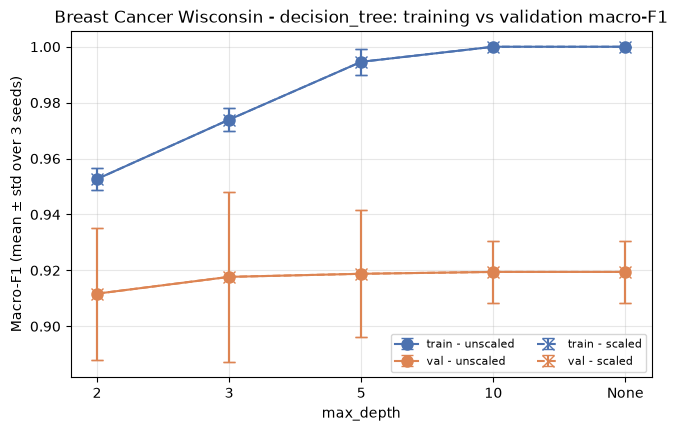

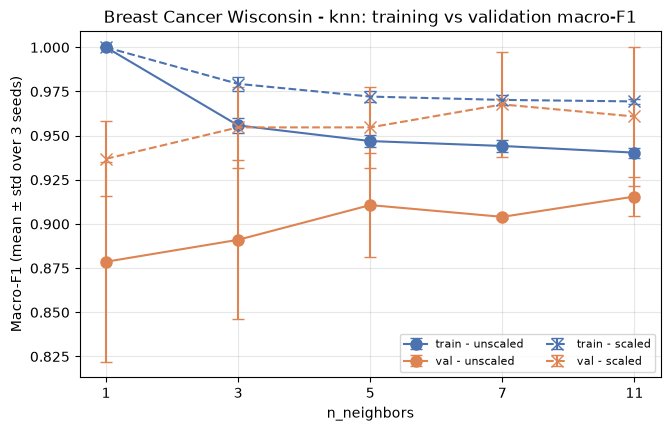

In [25]:
H.plot_param_curve(summary, "decision_tree", H.TREE_DEPTHS, "depth", "max_depth",
                   DATASET_TITLE, f"{DATASET}_tree_depth_macro_f1")
H.plot_param_curve(summary, "knn", H.KNN_NEIGHBORS, "k", "n_neighbors",
                   DATASET_TITLE, f"{DATASET}_knn_neighbors_macro_f1")

In [26]:
# Scaling effect: mean validation macro-F1 (scaled − unscaled) per setting
H.scaling_effect_table(summary)

representation           scaled  unscaled  scaled_minus_unscaled
algorithm     parameter                                         
knn           k7         0.9677    0.9040                 0.0636
              k3         0.9547    0.8910                 0.0636
              k1         0.9369    0.8786                 0.0583
              k11        0.9608    0.9155                 0.0453
              k5         0.9547    0.9107                 0.0440
decision_tree depth10    0.9195    0.9195                 0.0000
              depth2     0.9117    0.9117                 0.0000
              depth3     0.9177    0.9177                 0.0000
              depth5     0.9188    0.9188                 0.0000
              depthNone  0.9195    0.9195                 0.0000
gaussian_nb   default    0.9248    0.9369                -0.0121

In [27]:
# Training/validation gap per configuration
gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean", "val_macro_f1_std"]].copy()
gap["train_minus_val"] = gap.train_macro_f1_mean - gap.val_macro_f1_mean
gap.sort_values("train_minus_val", ascending=False)

,config_id,train_macro_f1_mean,val_macro_f1_mean,val_macro_f1_std,train_minus_val
5,breast_cancer_knn_unscaled_k1,1.0000,0.8786,0.0566,0.1214
3,breast_cancer_decision_tree_unscaled_depth10,1.0000,0.9195,0.0112,0.0805
4,breast_cancer_decision_tree_unscaled_depthNone,1.0000,0.9195,0.0112,0.0805
15,breast_cancer_decision_tree_scaled_depthNone,1.0000,0.9195,0.0112,0.0805
14,breast_cancer_decision_tree_scaled_depth10,1.0000,0.9195,0.0112,0.0805
2,breast_cancer_decision_tree_unscaled_depth5,0.9946,0.9188,0.0227,0.0758
13,breast_cancer_decision_tree_scaled_depth5,0.9946,0.9188,0.0227,0.0758
6,breast_cancer_knn_unscaled_k3,0.9558,0.8910,0.0449,0.0648
16,breast_cancer_knn_scaled_k1,1.0000,0.9369,0.0213,0.0631
1,breast_cancer_decision_tree_unscaled_depth3,0.9739,0.9177,0.0304,0.0562


> **Interpretation (write your own):** Discuss scaling effects (use numbers from the scaling table), how depth and k change performance, the train/validation gaps (overfitting, e.g. depth=None or k=1 reach training F1 = 1.0), and seed variability. The std describes these three repeated splits only; it is not a confidence interval.

## 9. Evaluating the Selected Model on the Test Set
Only the **seed-42** fitted instance of the selected configuration is evaluated, using seed-42 preprocessing.

In [28]:
final_model = models_s42[SELECTED_CONFIG]
final_rep = selected["representation"]
X_test_eval = test_reps[final_rep]
y_test_pred = final_model.predict(X_test_eval)
labels = list(final_model.classes_)
print("Final model:", final_model, "| representation:", final_rep)

Final model: KNeighborsClassifier(metric='euclidean', n_neighbors=7) | representation: scaled


### 9.1 Final performance metrics

In [29]:
test_metrics = H.classification_metrics(final_model, X_test_eval, y_test, DATASET, POSITIVE_LABEL)
classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": SELECTED_CONFIG, "eval_seed": H.EVAL_SEED,
    "mean_val_macro_f1": selected["val_macro_f1_mean"], "std_val_macro_f1": selected["val_macro_f1_std"],
    **{f"test_{k}": v for k, v in test_metrics.items()
       if k not in ("precision_undefined_classes", "recall_undefined_classes")},
}])
print("Undefined precision classes:", test_metrics["precision_undefined_classes"] or "none",
      "| undefined recall classes:", test_metrics["recall_undefined_classes"] or "none")
classifier_test

Undefined precision classes: none | undefined recall classes: none


,dataset,selected_config,eval_seed,mean_val_macro_f1,std_val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.9800,0.9643,0.9713,0.9888


In [30]:
print(classification_report(y_test, y_test_pred, labels=labels,
                            target_names=[f"{l}: {target_names[l]}" for l in labels],
                            digits=4, zero_division=0))
report_df = pd.DataFrame(classification_report(y_test, y_test_pred, labels=labels, output_dict=True,
                                               zero_division=0)).T

              precision    recall  f1-score   support

0: malignant     1.0000    0.9286    0.9630        42
   1: benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



### 9.2 Confusion matrix

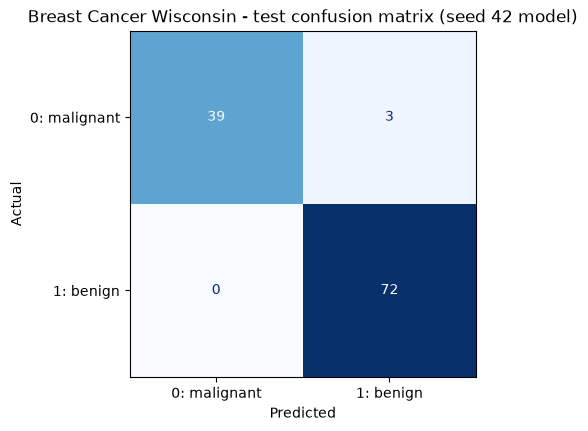

,Predicted 0: malignant,Predicted 1: benign
Actual 0: malignant,39,3
Actual 1: benign,0,72


In [31]:
cm_df = H.plot_confusion(y_test, y_test_pred, labels, target_names, DATASET_TITLE,
                         f"{DATASET}_test_confusion_matrix")
cm = cm_df.values
cm_df

In [32]:
# Class order [0, 1] = [malignant, benign]; malignant (0) is the POSITIVE class.
TP = cm[0, 0]   # actual malignant, predicted malignant
FN = cm[0, 1]   # actual malignant, predicted benign  (missed cancer)
FP = cm[1, 0]   # actual benign,    predicted malignant (false alarm)
TN = cm[1, 1]   # actual benign,    predicted benign
print(f"TP={TP}  FN={FN}  FP={FP}  TN={TN}")
print("Note: with order [malignant, benign] TP is top-left, NOT the usual bottom-right layout.")

TP=39  FN=3  FP=0  TN=72
Note: with order [malignant, benign] TP is top-left, NOT the usual bottom-right layout.


**Manual metric check** (compared with the per-class row of the classification report, not the macro average)

In [33]:
manual = H.manual_one_vs_rest(cm, labels, MANUAL_CHECK_CLASS)
rep_row = report_df.loc[str(MANUAL_CHECK_CLASS)]
tp, fp, fn = manual["TP"], manual["FP"], manual["FN"]
print(f"Class {MANUAL_CHECK_CLASS} ({target_names[MANUAL_CHECK_CLASS]}) vs rest: TP={tp}, FP={fp}, FN={fn}, TN={manual['TN']}")
print(f"precision = TP/(TP+FP) = {tp}/({tp}+{fp}) = {manual['precision']:.4f}" if tp + fp else "precision undefined (TP+FP=0)")
print(f"recall    = TP/(TP+FN) = {tp}/({tp}+{fn}) = {manual['recall']:.4f}" if tp + fn else "recall undefined (TP+FN=0)")
print(f"F1        = 2PR/(P+R)            = {manual['f1']:.4f}")
pd.DataFrame({"manual": [manual["precision"], manual["recall"], manual["f1"]],
              "classification_report": [rep_row["precision"], rep_row["recall"], rep_row["f1-score"]]},
             index=["precision", "recall", "f1"])

Class 0 (malignant) vs rest: TP=39, FP=0, FN=3, TN=72
precision = TP/(TP+FP) = 39/(39+0) = 1.0000
recall    = TP/(TP+FN) = 39/(39+3) = 0.9286
F1        = 2PR/(P+R)            = 0.9630


,manual,classification_report
precision,1.0000,1.0000
recall,0.9286,0.9286
f1,0.9630,0.9630


### 9.3 ROC curve

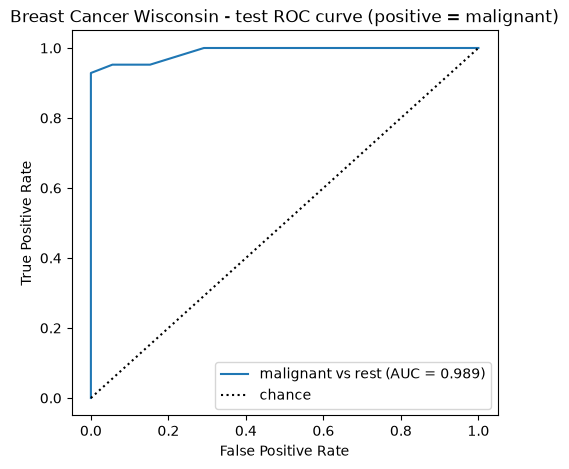

Malignant-vs-benign test ROC-AUC: 0.9888


In [34]:
auc_bc = H.plot_roc_binary(final_model, X_test_eval, y_test, POSITIVE_LABEL, target_names,
                           DATASET_TITLE, f"{DATASET}_test_roc")
print(f"Malignant-vs-benign test ROC-AUC: {auc_bc:.4f}")

### 9.4 Error interpretation

In [35]:
errors = H.misclassified_table(final_model, X_test_eval, y_test, target_names)
print("Misclassified test samples:", len(errors), "of", len(y_test))
errors

Misclassified test samples: 3 of 114


,true,predicted,P(class 0: malignant),P(class 1: benign)
41,0,1,0.4290,0.5710
73,0,1,0.1430,0.8570
205,0,1,0.1430,0.8570


> **Interpretation (write your own):** Compare validation vs test results (without changing the model), explain TP/FP/FN/TN with malignant as positive (an FN is a missed malignant tumour — the costliest error), describe how lowering/raising the decision threshold trades false positives against false negatives, describe one misclassified sample from the table above (or why zero errors does not prove perfect generalisation), and state a limitation (small validation subsets, overlapping repetitions, single seed-42 test).

## 10. K-Means Clustering
### 10.1 Fit on training features (no labels), 2 representations × 3 seeds = 6 fits

In [36]:
km_runs, km_models_s42 = H.run_kmeans(DATASET, reps, splits, N_CLUSTERS)
km_runs

,dataset,run_id,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette,val_n_distinct_clusters
0,breast_cancer,breast_cancer_kmeans_unscaled_c2_s42,42,unscaled,2,51565380.5448,0.3995,0.6387,2
1,breast_cancer,breast_cancer_kmeans_scaled_c2_s42,42,scaled,2,7918.8101,0.4516,0.2854,2
2,breast_cancer,breast_cancer_kmeans_unscaled_c2_s52,52,unscaled,2,49190782.1788,0.6122,0.6975,2
3,breast_cancer,breast_cancer_kmeans_scaled_c2_s52,52,scaled,2,8003.0010,0.5586,0.3750,2
4,breast_cancer,breast_cancer_kmeans_unscaled_c2_s62,62,unscaled,2,53056488.4035,0.5013,0.6958,2
5,breast_cancer,breast_cancer_kmeans_scaled_c2_s62,62,scaled,2,7922.5149,0.7336,0.2758,2


In [37]:
km_summary = H.summarise_kmeans(km_runs)
km_summary

,dataset,representation,train_inertia_mean,train_inertia_std,train_inertia_valid_seeds,val_ari_mean,val_ari_std,val_ari_valid_seeds,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_seeds
0,breast_cancer,unscaled,51270883.7090,1949606.9972,3,0.5043,0.1064,3,0.6773,0.0334,3
1,breast_cancer,scaled,7948.1087,47.5743,3,0.5813,0.1424,3,0.3121,0.0547,3


*Raw inertia is not comparable between the scaled and unscaled feature spaces (different units).*
### 10.2 Final cluster evaluation on the fixed test set (seed 42, no new fits)

In [38]:
km_test, contingency, test_clusters = H.kmeans_test_eval(DATASET, km_models_s42, test_reps, y_test, N_CLUSTERS)
km_test

,dataset,representation,eval_seed,n_clusters,n_test,test_ari,test_silhouette,cluster_0_count,cluster_1_count
0,breast_cancer,unscaled,42,2,114,0.5585,0.7120,86,28
1,breast_cancer,scaled,42,2,114,0.7354,0.3251,74,40


In [39]:
for rep in H.REPRESENTATIONS:
    print(f"Class-vs-cluster contingency table — {DATASET_TITLE}, {rep}, test set, seed-42 K-Means")
    display(contingency[rep])

Class-vs-cluster contingency table — Breast Cancer Wisconsin, unscaled, test set, seed-42 K-Means


cluster ID,0,1
true class,,
0,14,28
1,72,0


Class-vs-cluster contingency table — Breast Cancer Wisconsin, scaled, test set, seed-42 K-Means


cluster ID,0,1
true class,,
0,5,37
1,69,3


### 10.3 Visualise the clusters

Chosen features (highest ANOVA F on seed-42 training data, visualisation only): ['worst concave points', 'mean concave points']


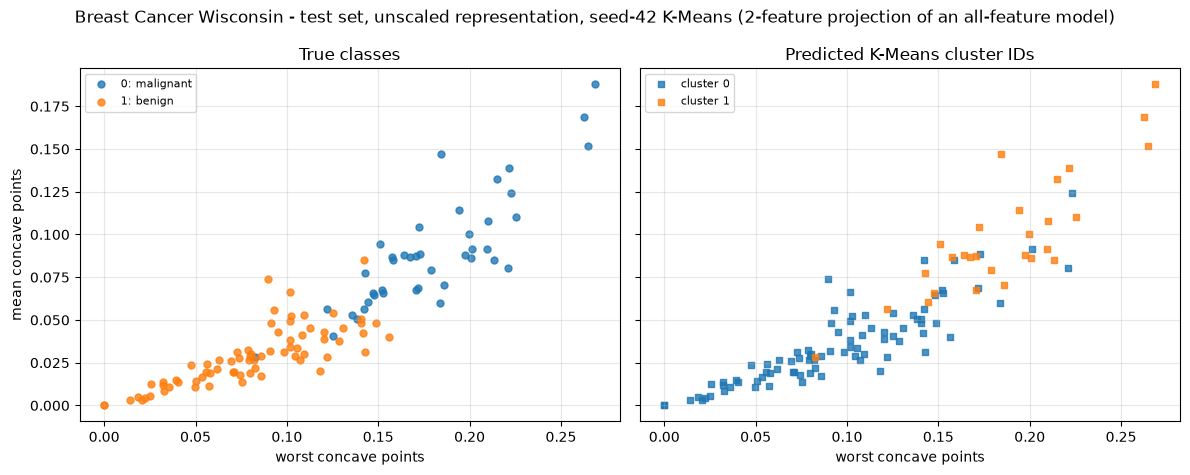

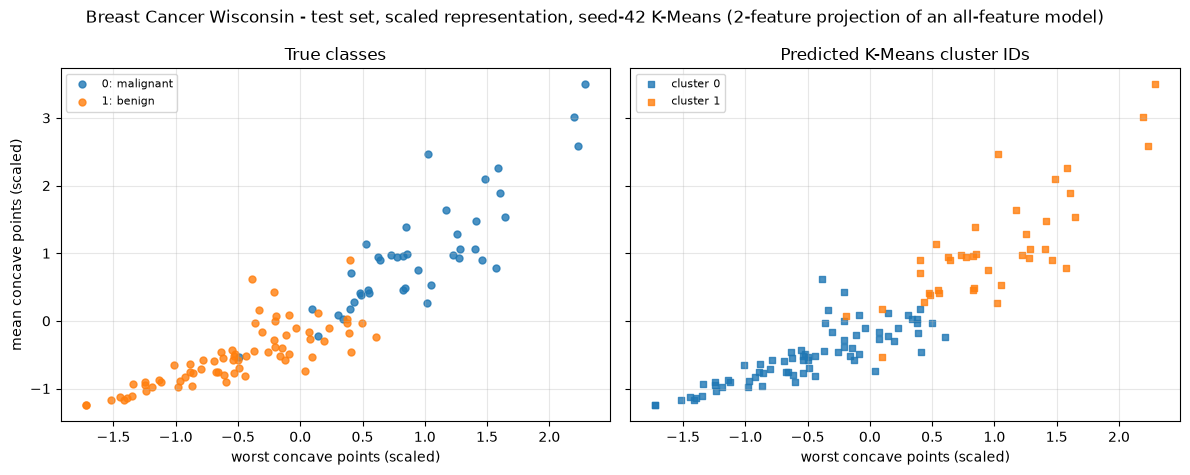

In [40]:
plot_features, f_scores = H.choose_plot_features(splits[42]["X_train"], splits[42]["y_train"])
print("Chosen features (highest ANOVA F on seed-42 training data, visualisation only):", plot_features)
for rep in H.REPRESENTATIONS:
    H.plot_class_vs_cluster(test_reps[rep], y_test, test_clusters[rep], plot_features, target_names, rep,
                            DATASET_TITLE, f"{DATASET}_kmeans_{rep}_class_vs_cluster")

> **Interpretation (write your own):** Use ARI and the contingency tables to say which classes are mixed within clusters and how scaling changed the partition (do not call ARI an accuracy). The plots are 2-feature projections of an all-feature model. Explain that K-Means never saw the labels during fitting, whereas the classifiers were trained with y_train.

## Export of result files (Section 12)
This notebook writes its own part; the six combined CSVs include every dataset whose notebook has been run.

In [41]:
export_status = H.export_results(DATASET, {
    "classifier_runs": runs, "classifier_summary": summary, "classifier_test": classifier_test,
    "kmeans_runs": km_runs, "kmeans_summary": km_summary, "kmeans_test": km_test,
})
export_status

,file,rows,expected_rows_both_datasets,datasets_included,complete
0,classifier_runs.csv,66,132,breast_cancer,False
1,classifier_summary.csv,22,44,breast_cancer,False
2,classifier_test.csv,1,2,breast_cancer,False
3,kmeans_runs.csv,6,12,breast_cancer,False
4,kmeans_summary.csv,2,4,breast_cancer,False
5,kmeans_test.csv,2,4,breast_cancer,False


In [42]:
print("Figures saved:", len(list(H.FIG_DIR.glob(f"{DATASET}_*.png"))))
sorted(p.name for p in H.FIG_DIR.glob(f"{DATASET}_*.png"))

Figures saved: 11


['breast_cancer_boxplots_1.png',
 'breast_cancer_boxplots_2.png',
 'breast_cancer_boxplots_3.png',
 'breast_cancer_class_distribution.png',
 'breast_cancer_correlation_heatmap.png',
 'breast_cancer_kmeans_scaled_class_vs_cluster.png',
 'breast_cancer_kmeans_unscaled_class_vs_cluster.png',
 'breast_cancer_knn_neighbors_macro_f1.png',
 'breast_cancer_test_confusion_matrix.png',
 'breast_cancer_test_roc.png',
 'breast_cancer_tree_depth_macro_f1.png']